# Individual homework project 2

You will apply statistical testing and correlation analysis to the ShopNow dataset.

For each question:

1. Run the appropriate test.
2. Report the test statistic and p-value (if applicable).
3. Interpret the result in plain English.
4. Explain what it means for the business.

In [2]:
# Import modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind, chi2_contingency, pearsonr

In [4]:
# Import datasets
customers = pd.read_csv("../../Data/customers.csv")
transactions = pd.read_csv("../../Data/transactions.csv")
sessions = pd.read_csv("../../Data/web_sessions.csv")
campaign = pd.read_csv("../../Data/campaign_touchpoints.csv")

### Specific questions

Q1. Do customers from the UK spend more per transaction than customers from Germany?

In [7]:
cust_trans = customers.merge(transactions, on = "customer_id")
cust_trans[(cust_trans["country"] == "UK") | (cust_trans["country"] == "Germany")].groupby("country")["purchase_value"].mean()

country
Germany    239.028571
UK         234.835997
Name: purchase_value, dtype: float64

In [9]:
# Is the difference meaningful? Let's run t-test and p-value to see if the difference is statistically significant. or it is just due to random chance.
# H0: There is no difference in the average purchase value between customers from the UK and Germany.
# H1: There is a difference in the average purchase value between customers from the UK and Germany.
UK = cust_trans[cust_trans["country"] == "UK"]["purchase_value"]
Germany = cust_trans[cust_trans["country"] == "Germany"]["purchase_value"]
t_stat, p_value = ttest_ind(UK, Germany)
print(f"p-value:{p_value:.2f}")
print(f"t_statistic: {t_stat:.2f}")



p-value:0.39
t_statistic: -0.86


The difference between the average purchase value for customers from Germany and customers from UK is approximately 4. which is not a significant.The statistical analysis supports this observation, With p_value = 0.39 > 0.05; we can say that there is no strong evidence of difference between the average purchase value of customers from the two countries. Therefore, we can maintain the null hypothesis.

Q2. Do discounted purchases differ in average value from non-discounted purchases?

In [11]:
df = transactions.groupby("discount_used")["purchase_value"].mean()
df

discount_used
0    234.564603
1    235.607418
Name: purchase_value, dtype: float64

In [21]:
# Statistical Analysis
# H0: There is no difference between discounted purchases and non-discounted purchases.
# H1: There is a difference between discounted purchases and non-discounted purchases.

No_discounted = cust_trans[cust_trans["discount_used"] == 0]["purchase_value"]
discounted = cust_trans[cust_trans["discount_used"] == 1]["purchase_value"]
t_stat, p_value = ttest_ind(No_discounted, discounted)
print(f"t-stat:{t_stat:.2f}")
print(f"p_value:{p_value:.2f}")

t-stat:-0.40
p_value:0.69


The difference between the average purchase values of discounted and non-discounted purchases is 1, which is relatively small. 
The statistical analysis supports this result, with a p_value = 0.69 > 0.05 and the t_stat= -0.49. Therefore, there is no strong evidence of difference, and the observed difference could be due to random variation.

Q3. Do male and female customers differ in average purchase value?

In [19]:
cust_trans[(cust_trans["gender"]=="Male") | (cust_trans["gender"]=="Female")].groupby("gender")["purchase_value"].mean()



gender
Female    235.938331
Male      234.811486
Name: purchase_value, dtype: float64

In [22]:
# Statistical Analysis
# H0: There is no difference between male and female average purchase values.
# H1: There is a difference between male and female average purchase values.

male = cust_trans[cust_trans["gender"]=="Male"]["purchase_value"]
female = cust_trans[cust_trans["gender"]=="Female"]["purchase_value"]
t_stat, p_value = ttest_ind(male,female)
print(f"t_stat:{t_stat:.2f}")
print(f"p_value:{p_value:.2f}")

t_stat:-0.39
p_value:0.70


From the statistical analysis, the p-value = 0.70 > 0.05,  we can conclude that there is no strong evidence of difference in average purchase value between male and female customers  because the p-value = 0.70 > 0.05.

Q4. Do customers acquired via email spend more than those from social channels?

In [ ]:
# Statistical Analysis
# H0: Customer acquired via email and social media have the same average purchase values.
# H1: Customer acquired via email and social media have different average purchase values.
merge_trans_sess = transactions.merge(sessions, on = "customer_id")
email = merge_trans_sess[merge_trans_sess["traffic_source"]=="email"]["purchase_value"]
social = merge_trans_sess[merge_trans_sess["traffic_source"]=="social"]["purchase_value"]
t_stat, p_value =ttest_ind(email, social)
print(f"t_stat:{t_stat:.2f}")
print(f"p_value:{p_value:.2f}")

t_stat:-0.03
p_value:0.98


From  the statistical analysis, we have the p_value =0.98 > 0.05, we can conclude that there is no strong difference between the average purchase values of customer acquired via email and via social media. The difference observed could be due to random variations. Therefore, we fail to reject the null hypothesis H0.

Q5. Is device type associated with conversion?

In [ ]:
# Statistical Analysis
# H0: Device_type is not associated with conversion
# H1: Device_type is associated with conversion
table = pd.crosstab(sessions["device_type"], sessions["converted"])
chi2, p_value, dof,expected = chi2_contingency(table)
print(f"chi_square:{chi2:.2f}")
print(f"p_value:{p_value:.2f}")


chi_square:1.15
p_value:0.56


How statistical analysis shows that p = 0.56 > 0.05 . Therefore there insufficient statistical evidence to conclude that there is an association between device type and conversion. 

Q6. Is acquisition channel associated with conversion?

In [38]:
cust_sess = customers.merge(sessions, on = "customer_id")
table = pd.crosstab(cust_sess["acquisition_channel"], cust_sess["converted"])
table

converted,0,1
acquisition_channel,,
Email,1708,277
email,11817,1771
organic,11079,1673
paid_Search,1206,160
paid_search,12003,1754
referral,11563,1746
social,11545,1798


In [40]:
# Some data in the acquisition_channel are not consistent. Example we have "Email" and "email"
cust_sess["acquisition_channel"]=cust_sess["acquisition_channel"].str.lower() 
table = pd.crosstab(cust_sess["acquisition_channel"], cust_sess["converted"])
table

converted,0,1
acquisition_channel,,
email,13525,2048
organic,11079,1673
paid_search,13209,1914
referral,11563,1746
social,11545,1798


In [ ]:
# Statistical Analysis
# H0: There is no association between acquisition channel and conversion.
# H1: There is an association between acquisition channel and conversion.
chi2, p_value, dof, expected = chi2_contingency(table)
print(f"chi_square:{chi2:.2f}")
print(f"p_value:{p_value:.2f}")

chi_square:4.31
p_value:0.37


The statistical analysis shows p = 0.37 which is greater than the reference value 0.05. Therefore there is no strong evidence to conclude that there is an association between acquisition channel and conversion. We fail to reject the H0 hypothesis.

Q7. Is product category associated with discount usage?

In [42]:
table = pd.crosstab(transactions["product_category"], transactions["discount_used"])
table


discount_used,0,1
product_category,,
beauty,5305,2281
electronics,5212,2212
fashion,5326,2255
home,5210,2278
sports,5225,2279
toys,5196,2221


In [ ]:
# Statistical Analysis
# H0: Product category is not associated with discount usage.
# H1: Product category is associated with discount usage.
chi2, p_value, dof, expected = chi2_contingency(table)
print(f"chi_square:{chi2:.2f}")
print(f"p_value:{p_value:.2f}")

chi_square:1.46
p_value:0.92


p_value = 0.92 > 0.05 : No strong evidence to conclude that product_category is associated with discount usage.
We fail to reject the null hypothesis.

Q8. Is time on site correlated with purchase value?

In [45]:
trans_sess = transactions.merge(sessions, on = "customer_id")
corr = trans_sess[["time_on_site", "purchase_value"]].corr()
corr



,time_on_site,purchase_value
time_on_site,1.000000,0.000164
purchase_value,0.000164,1.000000


From the statistical analysis, we have the correlation coefficient r =0.000164 which is a positive and very weak correlation. We can say that there is a very weak correlation between the two variables (almost no correlation). Therefore, spending more time on the site does not necessarily mean higher purchase.

Q9. Is number of pages viewed correlated with purchase value?

In [50]:
corr = trans_sess[["pages_viewed", "purchase_value"]].corr() 
corr 

,pages_viewed,purchase_value
pages_viewed,1.000000,-0.003584
purchase_value,-0.003584,1.000000


The correlation coefficient between pages_viewed and purchase_value is r = -0.003584 which is a very weak negative correlation close to 0. We can say that more page viewed does not always mean high purchase. 

In [99]:
r, p_value = pearsonr(trans_sess["pages_viewed"], trans_sess["purchase_value"])
print(r)
print(p_value)

-0.003584178041206562
0.044177583503879014


Q10. Is time on site correlated with pages viewed?

In [51]:
corr = sessions[["time_on_site", "pages_viewed"]].corr()
corr

,time_on_site,pages_viewed
time_on_site,1.00000,0.00454
pages_viewed,0.00454,1.00000


We have a very weak positive correlation between time on site and pages viewed (r = 0.00454). From the coefficient of correlation r, we can say that spending more time on site does not always mean more pages viewed.

### Challenges

C1. Explore whether high-spending customers behave differently in terms of session time.

Define “high spending” yourself.

In [59]:
# Let's assume that high spending customers are customers who have purchase greater than the average purchase value.
pvmean = transactions["purchase_value"].mean()
trans_sess["spending_group"] = trans_sess["purchase_value"].apply(lambda x: "High" if x > pvmean else "Low")
trans_sess.groupby("spending_group")["time_on_site"].mean()



spending_group
High    300.902775
Low     301.122294
Name: time_on_site, dtype: float64

In [60]:
# Statistical analysis
# H0 there is no difference between high spending customers and low spending customers in terms of session time
# H1 There is a difference between high spending customers and low spending customers in terms of session time
high = trans_sess[trans_sess["spending_group"] == "High"]["time_on_site"]
low = trans_sess[trans_sess["spending_group"] == "Low"]["time_on_site"]
t_stat, p_value = ttest_ind(high, low)
print(f"t_stat:{t_stat:.2f}")
print(f"p_value:{p_value:.2f}")




t_stat:-0.49
p_value:0.63


From the statistical analysis, we have p_value = 0.63 >0.05 . Therefore is not strong difference between the spending group category and the time on site. We do not reject the null hypothesis.

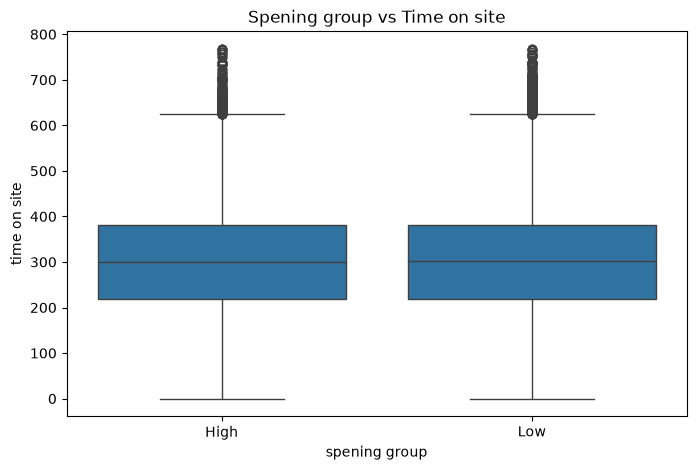

In [63]:
plt.figure(figsize = (8,5))
sns.boxplot (x = "spending_group", y = "time_on_site", data = trans_sess)
plt.title("Spening group vs Time on site")
plt.xlabel("spening group")
plt.ylabel("time on site")
plt.show()

C2. Find a relationship (difference or correlation) that you believe is meaningful for business strategy.

Explain why.

In [ ]:
# Are clicks associated with conversion?
#H0 clicks are not associated 
#H1 clicks and conversions are associated
table = pd.crosstab(campaign["clicked"], campaign["converted"])
table


converted,0,1
clicked,,
0,2946,0
1,2907,4147


In [79]:
chi22, p_value, dof, expected = chi2_contingency(table)
print(f"chi2:{chi2:.2f}")
print(f"p_value:{p_value:.5f}")


chi2:1.46
p_value:0.00000


In [103]:
r, p_value = pearsonr(campaign["clicked"], campaign["converted"])
print(f"r:{r:.3f}")
print(f"p_value:{p_value:.3f}")


r:0.544
p_value:0.000


From the statistical analysis, we have the coefficient of correlation r=0.54 this means that there is a moderated relationship between clicking and conversion. This is supported with the p_value = 0.00 < 0.05 , and it let us confirm that there is an evidence of relationship between the clicking and the conversion. Therefore, we reject the null hypothesis.
This relationship is important because it helps the company to understand if customers who clicked are more likely to convert. The company could use this information to evaluate its marketing activities.

c3. Identify a statistically significant result that may not be practically meaningful.

Explain why statistical significance ≠ business importance.

In [104]:
# Pages viewed and purchase value
r , p_value = pearsonr(trans_sess["pages_viewed"], trans_sess["purchase_value"])
print(f"r:{r:.3f}")
print(f"p_value:{p_value:.3f}")

r:-0.004
p_value:0.044


From the result, we have r = -0.004 with a p_value = 0.044 < 0.05 . The relationship between the pages viewed and purchase value is statistically significant because the p_value < 0.05 this means there is a strong evidence of relationship between the two variables. 
However, we have the correlation coefficient r = -0.004 which is close to close, indicating a negligible relationship between the two variables.

The two values p_value and r found in this case help us to understand that statistical significance does not always mean strong correlation or business importance. Although the relationship is statistically significant, its effect is extremely small and is unlikely to be useful for making business decision.